#### ▶ 비선형 이진 분류(등심원 데이터)

In [9]:
import torch
import matplotlib.pyplot as plt

#### Step 1. 데이터 생성

In [10]:
N = 100

# 0.3 주변의 값(50개)
radius1 = 0.3 + 0.05 * torch.randn(int(N/2), 1)     # 평균 0.3, 표준편차 0.05 숫자 50개
# 1 주변의 값(50개)
radius2 = 1 + 0.01 * torch.randn(int(N/2), 1)       # 평균 1, 표준편차 0.01 숫자 50개

# 각도 만들기
theta1 = 2 * torch.pi * torch.rand(int(N/2),1) - torch.pi        # -파이 ~ 파이의 값
theta2 = 2 * torch.pi * torch.rand(int(N/2),1) - torch.pi       

# (x, y) 좌표로 바꾸기 극좌표를 직교좌표로 변환
class1_data = torch.hstack([radius1 * torch.cos(theta1), radius2 * torch.sin(theta1)])
class2_data = torch.hstack([radius2 * torch.cos(theta2), radius2 * torch.sin(theta2)])

class1_label = torch.ones(int(N/2), 1)
class2_label = torch.zeros(int(N/2),1)

X = torch.vstack([class1_data, class2_data])
y = torch.vstack([class1_label, class2_label])

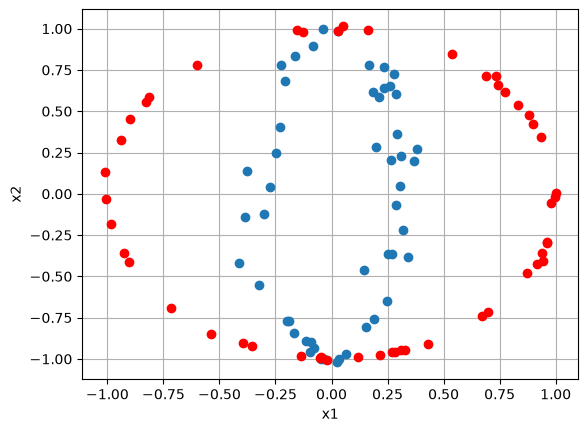

In [11]:
plt.plot(class1_data[:,0], class1_data[:,1], 'o')
plt.plot(class2_data[:,0], class2_data[:,1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()


#### Step 2. 모델 만들기

In [12]:
from torch import nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(2,100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid()
                                    )     
        
    def forward(self, x):
        x = self.linear(x)
        return x


In [13]:
model = MLP()

#### Step 3. 모델 학습 시키기

In [14]:
from torch import optim

LR = 1e-1
EPOCH = 100

optimizer = optim.Adam(model.parameters(), lr = LR)
# optimizer = optim.SGD(model.parameters(), lr = LR)        # 선형이 아니라 잘 안됨

cirterion = nn.BCELoss()

loss_history = []

model.train()       # train 모드로 변환
for ep in range(EPOCH):
    # inference
    y_hat = model(X)

    # loss
    loss = cirterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history += [loss.item()]

    # print
    print(f'EPOCH : {ep + 1}, train Loss : {loss.item():.4f}')
    print('-'*30)

EPOCH : 1, train Loss : 0.6966
------------------------------
EPOCH : 2, train Loss : 2.6128
------------------------------
EPOCH : 3, train Loss : 0.9371
------------------------------
EPOCH : 4, train Loss : 1.3428
------------------------------
EPOCH : 5, train Loss : 1.7483
------------------------------
EPOCH : 6, train Loss : 1.4031
------------------------------
EPOCH : 7, train Loss : 0.8349
------------------------------
EPOCH : 8, train Loss : 0.7387
------------------------------
EPOCH : 9, train Loss : 1.0400
------------------------------
EPOCH : 10, train Loss : 1.1689
------------------------------
EPOCH : 11, train Loss : 1.0653
------------------------------
EPOCH : 12, train Loss : 0.8498
------------------------------
EPOCH : 13, train Loss : 0.6985
------------------------------
EPOCH : 14, train Loss : 0.7280
------------------------------
EPOCH : 15, train Loss : 0.8429
------------------------------
EPOCH : 16, train Loss : 0.9016
------------------------------
E

Text(0, 0.5, 'Loss')

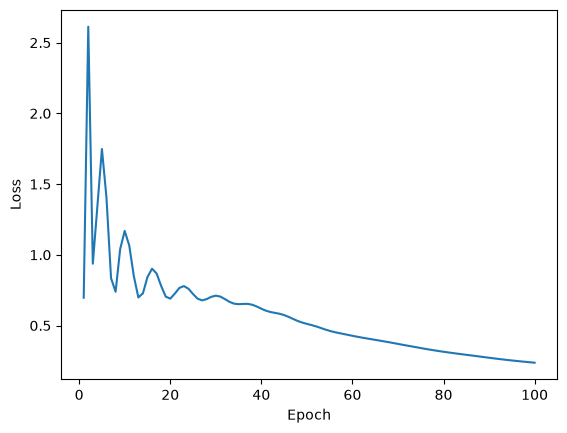

In [15]:
plt.plot(range(1,EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')

#### Step 4. 모델 테스트

Text(0.5, 0.5, 'x2')

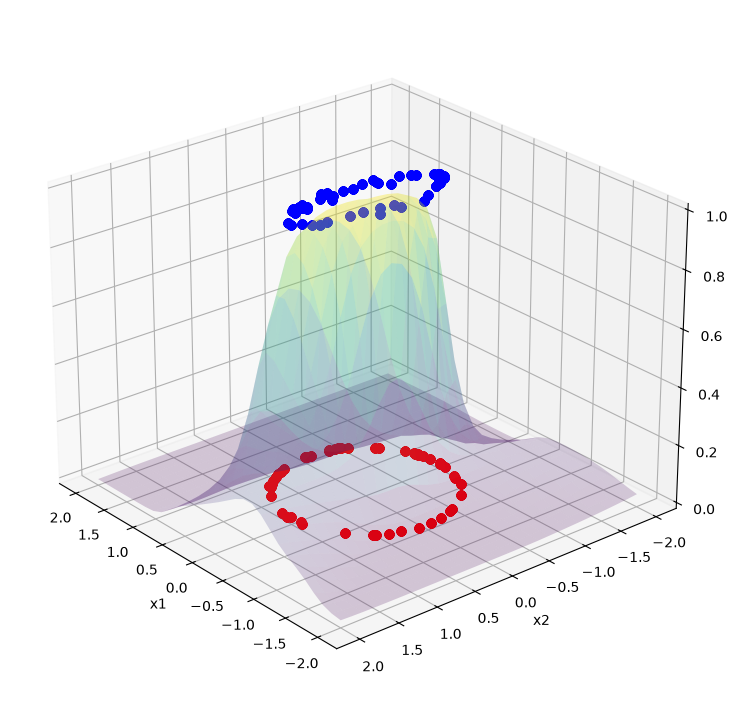

In [16]:
x1_test = torch.linspace(-2,2,30)
x2_test = torch.linspace(-2,2,30)

X1_test, X2_test = torch.meshgrid(x1_test, x2_test)
X_test = torch.cat([X1_test.unsqueeze(dim = 2), X2_test.unsqueeze(dim=2)], dim=2)

model.eval()        # test mode로 변환
with torch.no_grad() :
    y_hat = model(X_test)

Y_hat = y_hat.squeeze()

plt. figure(figsize=(10,9))
ax = plt.axes(projection = "3d")
ax.view_init(elev=25, azim = 140)

ax.plot_surface(X1_test, X2_test, Y_hat.numpy(), cmap='viridis', alpha=0.2)
plt.plot(class1_data[:,0], class1_data[:,1], class1_label, 'bo')
plt.plot(class2_data[:,0], class2_data[:,1], class2_label, 'ro')
plt.xlabel('x1')
plt.ylabel('x2')